# alluvial tutorial: how modules change

This tutorial draws alluvial diagrams of [Infomap](https://www.mapequation.org/infomap/) partitions with
`alluvial`. It covers how to:

1. compare the partitions of several Infomap runs,
2. choose a coloring,
3. show sub-modules,
4. highlight groups of nodes, with a legend,
5. draw state networks (multilayer and memory networks),
6. read Infomap output files,
7. make a multi-panel figure for a paper and save it as PDF, and
8. restyle single artists.

You need `pip install "alluvial[infomap]"`. Every network is built in the notebook and every Infomap run is
seeded, so the figures come out the same each time.

In [1]:
import random

import infomap
import matplotlib.pyplot as plt

import alluvial

## A small temporal network

Here 36 people work in teams of six, and teams that share a department collaborate. Over three years the
departments reorganize. In 2022 one team moves to another department, and in 2023 three departments become two.
For each year, links are drawn at random: dense within teams, sparser within departments, and rare between them.
`infomap.run` finds the modules of each year's network and returns an immutable `Result`. The network is an
`infomap.Network`, which carries the people's names.

In [2]:
NAMES = [
    "Ada",
    "Ben",
    "Cy",
    "Dee",
    "Eli",
    "Fay",
    "Gus",
    "Hal",
    "Ivy",
    "Jo",
    "Kai",
    "Lea",
    "Max",
    "Ned",
    "Ola",
    "Pia",
    "Quin",
    "Rex",
    "Sam",
    "Tia",
    "Uma",
    "Vic",
    "Wes",
    "Xia",
    "Yan",
    "Zoe",
    "Abe",
    "Bea",
    "Cal",
    "Dot",
    "Eve",
    "Fin",
    "Gil",
    "Hana",
    "Ike",
    "Jan",
]
TEAMS = [range(k, k + 6) for k in range(0, 36, 6)]  # six teams of six people
YEARS = ["2021", "2022", "2023"]
DEPARTMENTS = {  # the teams of each department, per year
    "2021": [[0, 1], [2, 3], [4, 5]],
    "2022": [[0, 1], [2, 3, 4], [5]],
    "2023": [[0, 1, 2], [3, 4, 5]],
}


def collaborations(departments, seed):
    "Random links: dense within teams, sparser within departments, rare between departments."
    rng = random.Random(seed)
    team = {u: t for t, members in enumerate(TEAMS) for u in members}
    dept = {t: d for d, teams in enumerate(departments) for t in teams}
    links = []
    for u in range(36):
        for v in range(u + 1, 36):
            if team[u] == team[v]:
                p = 0.7
            elif dept[team[u]] == dept[team[v]]:
                p = 0.12
            else:
                p = 0.01
            if rng.random() < p:
                links.append((u, v))
    return links


links = {year: collaborations(DEPARTMENTS[year], seed=i) for i, year in enumerate(YEARS)}


def run_infomap(links):
    "One seeded Infomap run on a named network."
    network = infomap.Network().add_nodes(enumerate(NAMES)).add_links(links)
    return infomap.run(network, seed=42, num_trials=10)


results = [run_infomap(links[year]) for year in YEARS]
for year, result in zip(YEARS, results):
    nf = alluvial.read(result)  # the partition as alluvial reads it
    paths = [node.path.split(":") for node in nf.nodes]  # "1:2:3": module 1, sub-module 2, node 3
    top_modules = {path[0] for path in paths}
    levels = max(map(len, paths))
    print(f"{year}: {len(top_modules)} top modules, {levels} levels, codelength {nf.codelength:.3f} bits")

2021: 4 top modules, 3 levels, codelength 3.614 bits
2022: 4 top modules, 3 levels, codelength 3.787 bits
2023: 4 top modules, 3 levels, codelength 4.093 bits


## One diagram for several runs

Pass the Infomap results from left to right. Each column is a network, and each block a module, with its height
proportional to the module's flow. A streamline joins two modules and is as thick as the flow of the nodes they
share. Nodes are matched across networks by node id. Modules carry the names of their largest nodes (by flow) on the
first and last network.

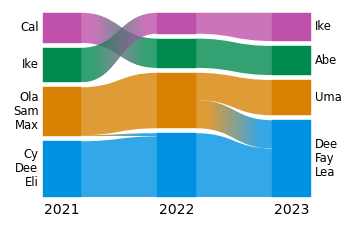

In [3]:
ax = alluvial.plot(results, names=YEARS)

Without `ax=`, `plot` makes its own figure, sized by its content: taller with more modules, wider with more
networks and longer labels. For anything you publish, give it an axes. The shapes then stretch to fill the axes,
while every font size and gap stays in points.

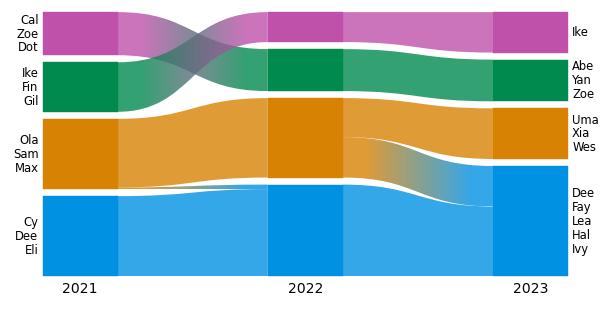

In [4]:
fig, ax = plt.subplots(figsize=(6, 3), layout="constrained")
alluvial.plot(results, ax=ax, names=YEARS);

## Colors

`colors=` picks how modules are colored. Every option is an operation of the web app:

- `"module_id"` (the default) gives each module id one color, the same in every network,
- `"similarity"` gives matching modules in neighboring networks the same color,
- `"nodes"` colors every node by its module in one network, so you can see where each module goes,
- `"hierarchy"` gives sub-modules colors close to their parent's (see the next section), and
- `None` leaves everything gray.

A module id is a number, not a name. Infomap numbers the modules by flow, largest first, so the numbers change
when modules change size. Here the two teams at the top, labeled Cal and Ike, swap numbers between 2021 and 2022:

2021: Cal's team is module 4, Ike's team is module 3
2022: Cal's team is module 3, Ike's team is module 4
2023: Cal's team is module 3, Ike's team is module 4


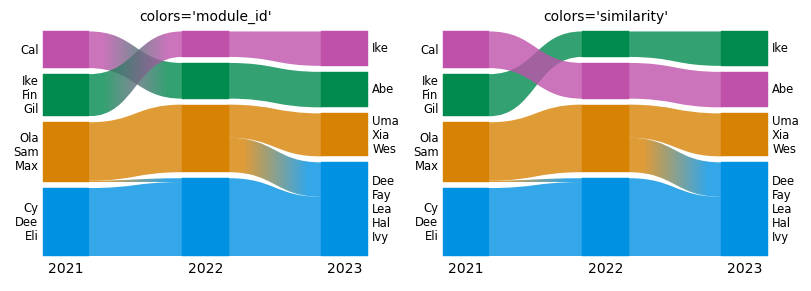

In [5]:
for year, result in zip(YEARS, results):
    module = {node.name: node.path.split(":")[0] for node in alluvial.read(result).nodes}
    print(f"{year}: Cal's team is module {module['Cal']}, Ike's team is module {module['Ike']}")

fig, axs = plt.subplots(1, 2, figsize=(8, 2.8), layout="constrained")
for ax, colors in zip(axs, ["module_id", "similarity"]):
    alluvial.plot(results, ax=ax, names=YEARS, colors=colors)
    ax.set_title(f"colors={colors!r}", fontsize="medium")


With `"module_id"`, the two teams swap colors in 2022, and their streamlines change color on the way. With
`"similarity"`, each team keeps its color, because modules are matched by the nodes they share.

`"nodes"` paints every node by its module in one network, the *color network*, and keeps that color in every
network. `color_network=` picks it, as selecting a network does in the web app: an index, a network id, or a name
given with `names=`. The default is the first network. Coloring by the first network shows where each module goes;
coloring by the last shows where each module came from.

`scheme=` picks one of the web app's color schemes (`alluvial.SCHEMES`), and `palette=` recolors at draw time with
a list of colors or a matplotlib colormap, for example `palette="tab10"`.


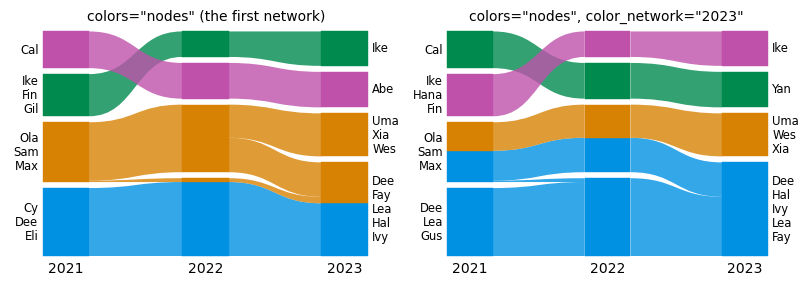

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(8, 2.8), layout="constrained")
alluvial.plot(results, ax=axs[0], names=YEARS, colors="nodes")
alluvial.plot(results, ax=axs[1], names=YEARS, colors="nodes", color_network="2023")
axs[0].set_title('colors="nodes" (the first network)', fontsize="medium")
axs[1].set_title('colors="nodes", color_network="2023"', fontsize="medium");

## Sub-modules

Infomap finds a hierarchy of modules: here, departments with teams inside. `module_level=2` opens every module that
has sub-modules (the same as clicking it in the web app). Pass one level per network to open only some of them, for
example `module_level=[2, 1, 1]`. Gray boxes behind the sub-modules mark their parent module, as in the web app.
`hierarchy="outline"` draws a solid dark gray line around each parent instead, and `hierarchy=False` draws nothing.

Sub-modules are colored like any other module. With the default `"module_id"`, a sub-module's color follows its
path, such as `"1:2"`, so the same path has the same color in every network. `colors="hierarchy"` gives sub-modules
colors close to their parent's. `colors="similarity"` pairs modules one at a time, as the web app does, and a
module it cannot pair stays gray.

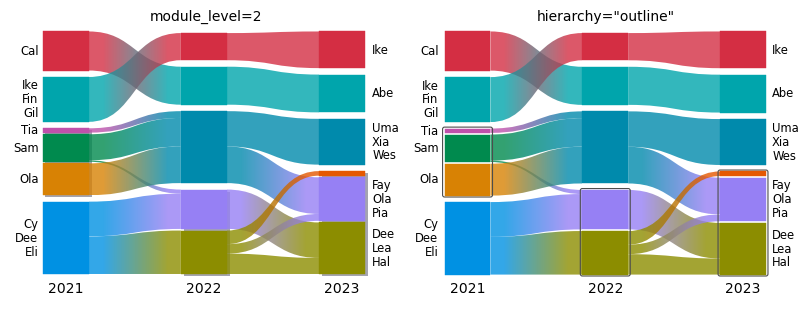

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(8, 3), layout="constrained")
alluvial.plot(results, ax=axs[0], names=YEARS, module_level=2)
alluvial.plot(results, ax=axs[1], names=YEARS, module_level=2, hierarchy="outline")
axs[0].set_title("module_level=2", fontsize="medium")
axs[1].set_title('hierarchy="outline"', fontsize="medium");

`expand=[(network, module_id), ...]` opens single modules instead. `network` is an index (or a network id), and
`module_id` is a module path such as `"1"` or `"1:2"`. Here we open module 2 of 2021 only, the department whose
two teams Infomap tells apart. Expanding a module without sub-modules raises `ValueError`.

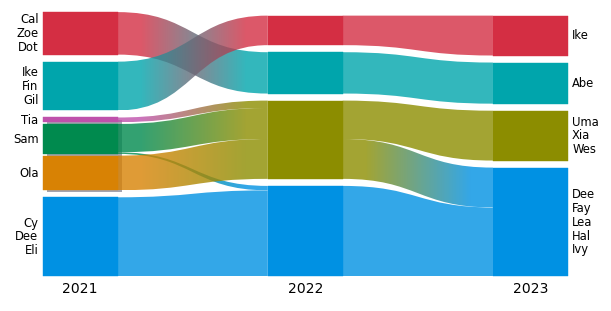

In [8]:
fig, ax = plt.subplots(figsize=(6, 3), layout="constrained")
alluvial.plot(results, ax=ax, names=YEARS, expand=[(0, "2")]);

## Highlighting groups of nodes

`highlight=` colors chosen nodes wherever they go and leaves the rest gray. It takes `{label: node ids}`, and
`legend=True` adds a legend. The label lines take the color of their node. Here we follow two teams.

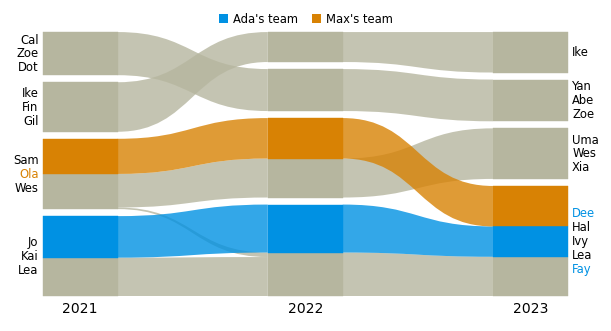

In [9]:
teams = {"Ada's team": TEAMS[0], "Max's team": TEAMS[2]}  # node ids
fig, ax = plt.subplots(figsize=(6, 3.2), layout="constrained")
alluvial.plot(results, ax=ax, names=YEARS, highlight=teams, legend=True);

With `identifier="name"`, nodes are matched by name, and `highlight` takes names too. `highlight` also accepts a
function that gets an `alluvial.NodeInfo` (network, id, name, flow, module path, metadata) and returns a label or
`None`. `alluvial.legend(ax, ...)` replaces the legend and takes the keywords of `Axes.legend`. `other=` adds an
entry for the gray nodes.

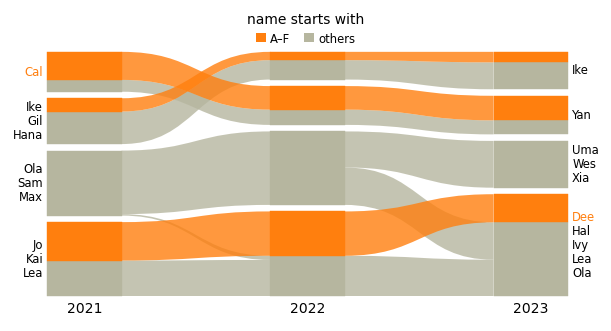

In [10]:
def first_letter(node):
    return "A–F" if node.name[0] <= "F" else None


fig, ax = plt.subplots(figsize=(6, 3.2), layout="constrained")
alluvial.plot(
    results,
    ax=ax,
    names=YEARS,
    identifier="name",
    highlight=first_letter,
    highlight_colors=["tab:orange"],
)
alluvial.legend(ax, other="others", title="name starts with", ncols=2);

## State networks: multilayer and memory

The three years can also be one multilayer network, with one layer per year. A single Infomap run then finds
modules that span the years. A multilayer network is a *state network*: each person has one state node per layer.
`alluvial` reads the state nodes and labels them by their physical names. `split_layers=True` draws one network per
layer and matches the layers by physical node, as the web app's "split layers" does.

5 modules across 3 layers


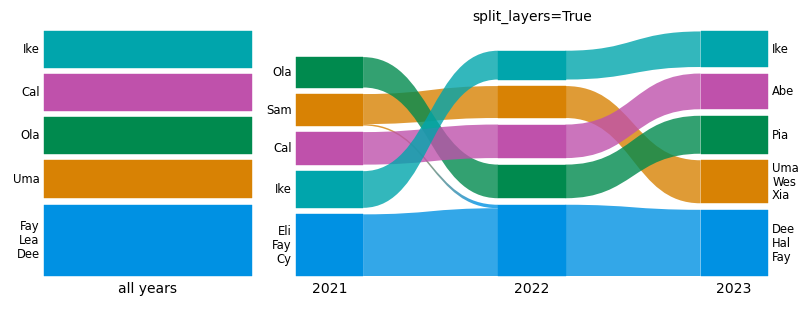

In [11]:
network = infomap.Network().set_names(dict(enumerate(NAMES)))
for layer, year in enumerate(YEARS, start=1):
    for u, v in links[year]:
        network.add_multilayer_intra_link(layer, u, v)
ml = infomap.run(network, seed=42, num_trials=10)  # relax rate: Infomap's default, 0.15
top_modules = {node.path.split(":")[0] for node in alluvial.read(ml).nodes}
print(f"{len(top_modules)} modules across {len(YEARS)} layers")

fig, axs = plt.subplots(1, 2, figsize=(8, 3), layout="constrained", width_ratios=[1, 2.2])
alluvial.plot([ml], ax=axs[0], names=["all years"])
alluvial.plot([ml], ax=axs[1], split_layers=True, names=YEARS)
axs[1].set_title("split_layers=True", fontsize="medium");

Memory (higher-order) networks work the same way. Their nodes are state nodes too.

Matching state networks with each other needs care. With the default `identifier="id"`, state nodes are matched by
state id. That is right only if the state ids mean the same thing in every network. Use `identifier="name"` to match
by physical node name instead. Do not mix state networks and ordinary networks under `identifier="id"`: a state id
would be compared with a node id. `alluvial` warns when you do.

## Reading Infomap output files

Infomap's output files work as inputs: `.tree`, `.ftree`, `.clu`, the state versions `.stree`/`*_states.tree`, and
`-o json`. The format comes from the suffix. The default network name is the file name. Below we write the three
runs from Python, which gives the same files as the command line `infomap net.net out/ -o tree,ftree,json`.

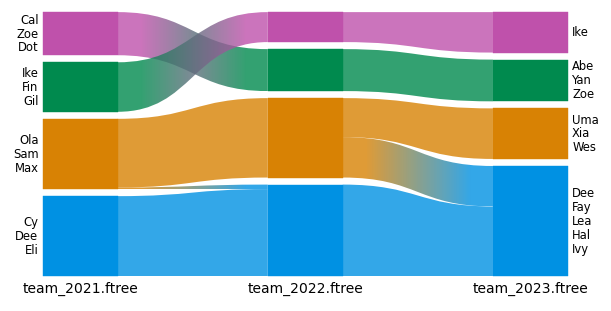

In [12]:
from pathlib import Path

out = Path("tutorial_output")
out.mkdir(exist_ok=True)
for year, result in zip(YEARS, results):
    result.write_flow_tree(out / f"team_{year}.ftree")

paths = [out / f"team_{year}.ftree" for year in YEARS]
fig, ax = plt.subplots(figsize=(6, 3), layout="constrained")
alluvial.plot(paths, ax=ax);

`alluvial.read` returns the parsed `NetworkFile`, which is useful for checking what was read. `alluvial.layout`
returns the geometry without drawing it: every module's position, flow and label, in a frozen dataclass.

In [13]:
nf = alluvial.read(paths[0])
print(nf.name, nf.format, len(nf.nodes), "nodes, codelength", nf.codelength)
node = nf.nodes[0]
print(f"first node: {node.name!r}, module path {node.path}, flow {node.flow}")

geom = alluvial.layout(paths, names=YEARS)
for module in geom.networks[0].modules:
    print(f"module {module.id}: flow {module.flow:.3f}, label {module.largest_leaf_names}")

team_2021.ftree ftree 36 nodes, codelength 3.61403
first node: 'Cy', module path 1:1, flow 0.0328947
module 1: flow 0.329, label ('Cy', 'Dee', 'Eli', 'Fay', 'Gus', 'Jo', 'Kai', 'Lea', 'Hal', 'Ada', 'Ben')
module 2: flow 0.289, label ('Ola', 'Sam', 'Max', 'Ned', 'Quin', 'Xia', 'Wes', 'Pia', 'Uma', 'Tia', 'Rex')
module 3: flow 0.204, label ('Ike', 'Fin', 'Gil', 'Hana', 'Eve', 'Jan')
module 4: flow 0.178, label ('Cal', 'Zoe', 'Dot', 'Abe', 'Bea', 'Yan')


## Naming and ordering modules

For a figure you usually want named modules in a fixed order. `module_names` replaces a module's node-name label
by your own name, and `module_order` stacks modules bottom to top. Both refer to modules by network and module id.
A network is its index (`0`, `1`, ...), its network id, or the name given with `names=` (as a string). A module id is a string,
`"3"`, or `"3:1"` after `module_level=2` or `expand`. Get the ids from a plain `layout` first:

In [14]:
geometry = alluvial.layout(results, names=YEARS)
for network in geometry.networks:
    print(network.index, network.id, network.name, [module.id for module in network.modules])

0 net0 2021 ['1', '2', '3', '4']
1 net1 2022 ['1', '2', '3', '4']
2 net2 2023 ['1', '2', '3', '4']


Module ids are per network: module `"1"` of 2021 and module `"1"` of 2022 are unrelated. To name the same
group consistently across years, pass a callable. It gets a `ModuleInfo` for every module (`node_names`,
`flow`, `id`, `network_index`, ...) and returns a name, or `None` to keep the node names. Here a module is named
after the teams with at least four of their six members in it.

`module_order={network: [module_id, ...]}` lists modules bottom to top. `...` stands for the modules you do not
list, which keep their order, so `[m, ...]` puts module `m` at the bottom and `[..., m]` at the top. Below, the
module with Ada is at the bottom in every year, and each network gets its own id from Infomap's partition.

{0: ['1', Ellipsis], 1: ['1', Ellipsis], 2: ['1', Ellipsis]}


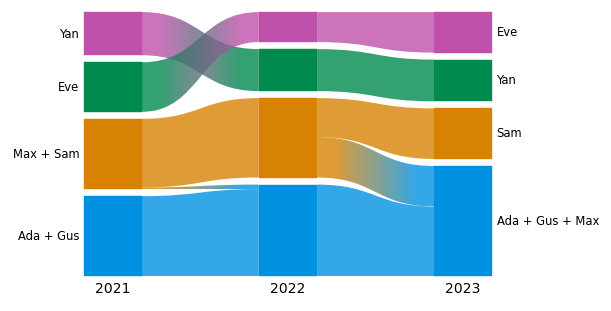

In [15]:
LEADERS = {NAMES[team[0]]: team for team in TEAMS}  # each team by its first member


def team_name(module):
    "Name a module after the teams that have at least four of their members in it."
    members = set(module.node_names)
    teams = [leader for leader, team in LEADERS.items() if sum(NAMES[u] in members for u in team) >= 4]
    return " + ".join(teams) or None


def module_of(result, name):
    "The top module of the node with this name."
    node = next(node for node in alluvial.read(result).nodes if node.name == name)
    return node.path.split(":")[0]


ada_at_bottom = {i: [module_of(result, "Ada"), ...] for i, result in enumerate(results)}
print(ada_at_bottom)

fig, ax = plt.subplots(figsize=(6, 3), layout="constrained")
alluvial.plot(results, ax=ax, names=YEARS, module_names=team_name, module_order=ada_at_bottom);

Some things to know:

- Names are drawn as labels on the first and last network only, as in the web app. Names of middle networks
  are kept (`ModuleGeometry.name`) but not drawn.
- Only visible modules can be ordered. A module below `flow_threshold` raises an error.
- `module_order` reorders all listed modules with one layout, so it stays fast with hundreds of sub-modules.
  "Move up/down" in the web app gives the same order.
- `save_diagram` stores the names and the custom order, and `layout` of the saved files restores them.

Wrong ids raise an error that says what is wrong:

In [16]:
mistakes = {
    "a year as an int (an int is an index)": dict(module_order={2021: ["1"]}),
    "a module id as an int": dict(module_order={0: [1]}),
    "a top module after module_level=2": dict(module_level=2, module_names={(0, "2"): "Department"}),
    "a hidden module": dict(flow_threshold=0.19, module_order={0: ["4"]}),
}
for what, kwargs in mistakes.items():
    try:
        alluvial.layout(results, names=YEARS, **kwargs)
    except (TypeError, ValueError) as error:
        print(f"{what}:\n  {type(error).__name__}: {error}")

a year as an int (an int is an index):
  ValueError: module_order: no network 2021 (the diagram has 3 networks; to refer to the network named '2021', pass the string '2021')
a module id as an int:
  TypeError: module_order[0]: module ids are strings like '1' or '1:2' (or ...), got 1
a top module after module_level=2:
  ValueError: module_names: no module '2' in network 'net0' (it is already expanded: its sub-modules are shown)
a hidden module:
  ValueError: module_order: module '4' in network 'net0' is not shown (its flow is below the flow threshold, or zero); only visible modules can be placed


## A figure for a paper

Set your paper's font in `rcParams`; every font size in the diagram follows `font.size`. Pass your own axes, use
`layout="constrained"`, and save as PDF. Labels and limits are fitted again whenever the figure is drawn, so text
keeps its point size and stays inside each panel. Long names are cut with an ellipsis, and a label that would
collide with its neighbor loses lines.

figure.pdf: 20 KiB


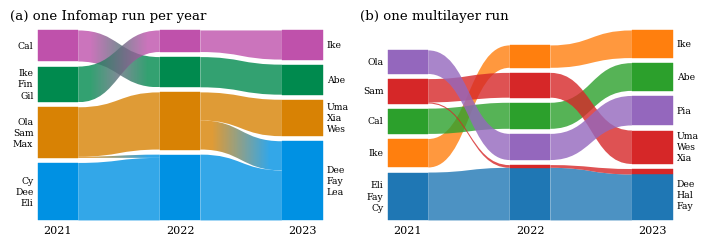

In [17]:
with plt.rc_context({"font.family": "serif", "font.size": 8, "pdf.fonttype": 42}):
    fig, (a, b) = plt.subplots(1, 2, figsize=(7, 2.4), layout="constrained")
    alluvial.plot(results, ax=a, names=YEARS, max_label_lines=3)
    alluvial.plot([ml], ax=b, split_layers=True, names=YEARS, colors="nodes", palette="tab10")
    a.set_title("(a) one Infomap run per year", loc="left")
    b.set_title("(b) one multilayer run", loc="left")
    fig.savefig(out / "figure.pdf")
    fig.savefig(out / "figure.png", dpi=300)

print(f"figure.pdf: {(out / 'figure.pdf').stat().st_size / 1024:.0f} KiB")

The PDF stays vector. A streamline between two colors is a small gradient image clipped to its outline, and
`gradient=False` makes it a single color. `rasterized=True` rasterizes only the shapes of a very large diagram and
keeps the text as vector.

## Tweaking artists

`plot` and `draw` return the axes. `alluvial.get_artists(ax)` returns the matplotlib artists they created, for any
change the keyword arguments do not cover. Every artist has a `gid` (`module:<network>:<module>:<group>`,
`streamline:<id>`, ...), and SVG output keeps it as the element id.

12 module rectangles, 10 streamlines


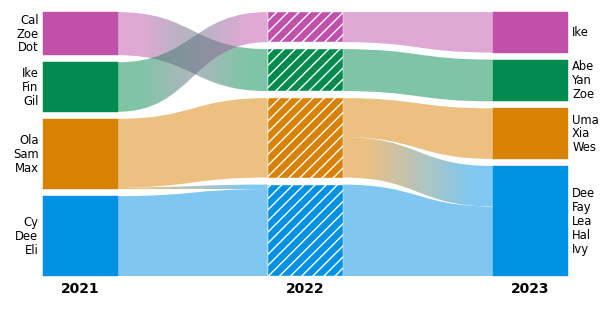

In [18]:
fig, ax = plt.subplots(figsize=(6, 3), layout="constrained")
alluvial.plot(results, ax=ax, names=YEARS, streamline_kw={"alpha": 0.5})
art = alluvial.get_artists(ax)
print(len(art.modules), "module rectangles,", len(art.streamlines), "streamlines")

for text in art.network_labels:
    text.set_fontweight("bold")
for rect in art.modules:
    if rect.get_gid().startswith("module:net1:"):  # the middle network (networks get ids net0, net1, ...)
        rect.set(
            hatch="///", edgecolor="white"
        )  # hatches take the edge color, which is the face color by default

## Open in the web app

`alluvial.save_diagram` takes the same arguments as `layout` and saves the diagram for the
[web app](https://www.mapequation.org/alluvial), where you can fine-tune it by hand: move and name modules, recolor,
change the layout. It writes the web app's "Download diagram" format, one Infomap JSON file per network in a `.zip` (or loose files
with `loose=True`): drop the zip on the web app's load dialog. The files keep the networks, their names, the colors,
the expanded modules, the layout options, the color scheme, module names and custom module orders.

`alluvial.read` loads the `.zip` back as one network per file, and `layout`/`plot` restore the diagram from them.
(The 2019 saved-diagram format, one `.json` with all networks, is no longer supported.)

['2021', '2022', '2023'] palette ['#0091e3', '#d88204', '#008a4e']


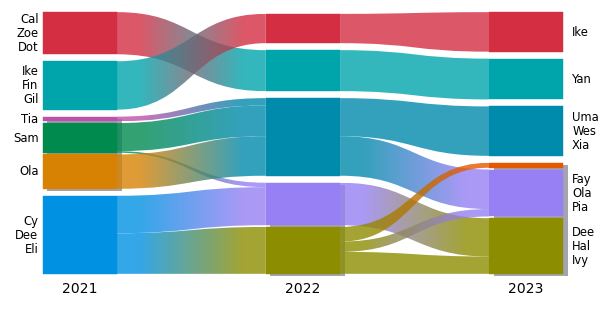

In [19]:
kwargs = dict(names=YEARS, module_level=2)
alluvial.save_diagram(results, out / "teams.zip", **kwargs)

saved = alluvial.read(out / "teams.zip")
print([nf.name for nf in saved], "palette", saved[0].colors[:3])
fig, ax = plt.subplots(figsize=(6, 3), layout="constrained")
alluvial.plot(saved, ax=ax);

## Common mistakes

`alluvial` raises or warns where a diagram would silently be wrong:

- an Infomap object that has not run raises `ValueError: ... call im.run() first`,
- a missing file raises `FileNotFoundError`,
- `highlight` identifiers that match no node, and a `module_level` deeper than a network's module tree, give a
  warning.

In [20]:
import warnings

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    alluvial.layout(results[:2], highlight={"typo": ["Adaa"]}, identifier="name")
    alluvial.layout(results[:2], module_level=4)
for w in caught:
    print("warning:", w.message)

## Next steps

- `help(alluvial.layout)` and `help(alluvial.draw)` list every option. The layout options (`height`,
  `module_width`, `flow_threshold`, `sort_modules_by`, ...) are the web app's.
- Partitions from other methods work too: a dict `{node: module}` per network, `alluvial.partition(modules,
  flows)`, or a pandas DataFrame with the columns `network`, `node` and `module` (see `docs/capabilities.ipynb`,
  section 1.1).
- The package README has more examples, including Infomap output files with longer node names.